In [ ]:

!pip install librosa soundfile --quiet

import numpy as np
import torch
import torch.nn as nn
import librosa
import pandas as pd
import pickle
import shutil
import gc
import os
import random
import warnings
from pathlib import Path
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

def set_all_seeds(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_all_seeds(42)

from google.colab import drive
drive.mount('/content/drive', force_remount=True)

MODELS_DIR  = Path('/content/drive/MyDrive/ICAST_Project/models')
RESULTS_DIR = Path('/content/drive/MyDrive/ICAST_Project/results')
CHARTS_DIR  = Path('/content/drive/MyDrive/ICAST_Project/charts')
device      = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f'Device: {device}')
print('\nModels in Drive:')
for f in sorted(MODELS_DIR.iterdir()):
    size_mb = f.stat().st_size / (1024**2)
    print(f'  {f.name:35s}  {size_mb:.2f} MB')
print('\nCell 1 done.')

ValueError: mount failed

In [ ]:
from google.colab import files
import os

# This will open a file picker. Select your downloaded kaggle.json file
files.upload()

# Create the .kaggle directory if it doesn't exist
os.makedirs('~/.kaggle', exist_ok=True)

# Move the uploaded file to the correct directory
!mv kaggle.json ~/.kaggle/

# Set the correct permissions (Kaggle API requires this for security)
!chmod 600 ~/.kaggle/kaggle.json

print("✅ Kaggle API token configured successfully!")

Saving kaggle.json to kaggle.json
mv: cannot move 'kaggle.json' to '/root/.kaggle/': Not a directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
✅ Kaggle API token configured successfully!


In [ ]:
# Ensure the kaggle package is installed (it usually is in Colab, but this is safe)
!pip install -q kaggle

import os

# Define where you want to save the dataset
download_dir = '/content/asvspoof2019'
os.makedirs(download_dir, exist_ok=True)

print("Downloading ASVspoof 2019 LA dataset via Kaggle API...")
print("This may take a few minutes depending on your Colab instance.\n")

# Download the dataset (using the anishsarkar22 mirror which contains the LA partition)
# The -p flag specifies the download path, -q makes it quiet, --unzip extracts it automatically
!kaggle datasets download -d anishsarkar22/asvpoof-2019-dataset-la -p {download_dir} --unzip

print("\n✅ Download and extraction complete!")

This may take a few minutes depending on your Colab instance.

Dataset URL: https://www.kaggle.com/datasets/anishsarkar22/asvpoof-2019-dataset-la
License(s): ODC Attribution License (ODC-By)
100% 7.12G/7.12G [02:00<00:00, 63.4MB/s]


✅ Download and extraction complete!


In [ ]:
# This downloads ~7 GB directly into Colab
# Takes 10-15 minutes — do not close the tab

import os
os.makedirs('/content/asvspoof2019', exist_ok=True)

print('Downloading ASVspoof 2019 LA from Edinburgh DataShare...')
print('Do NOT close this tab.\n')

!wget --no-check-certificate \
    "https://datashare.ed.ac.uk/bitstream/handle/10283/3336/LA.zip" \
    -O /content/asvspoof2019/LA.zip \
    --progress=bar:force 2>&1

# Check file size
size_gb = os.path.getsize('/content/asvspoof2019/LA.zip') / (1024**3)
print(f'\nDownloaded: {size_gb:.2f} GB')

if size_gb > 1.0:
    print('Download successful. Unzipping now (5 minutes)...')
    !unzip -q /content/asvspoof2019/LA.zip -d /content/asvspoof2019/
    print('Unzip complete.')
    print('\nContents:')
    !ls /content/asvspoof2019/LA/
else:
    print('Download failed — file too small. Try running this cell again.')

Do NOT close this tab.

--2026-08-23 20:14:03--  https://datashare.ed.ac.uk/bitstream/handle/10283/3336/LA.zip
Resolving datashare.ed.ac.uk (datashare.ed.ac.uk)... 129.215.67.172
Connecting to datashare.ed.ac.uk (datashare.ed.ac.uk)|129.215.67.172|:443... connected.
HTTP request sent, awaiting response... 403 Forbidden
2026-08-23 20:14:04 ERROR 403: Forbidden.


Downloaded: 0.00 GB
Download failed — file too small. Try running this cell again.


In [ ]:
LA_DIR     = Path('/content/asvspoof2019/LA')
EVAL_AUDIO = LA_DIR / 'ASVspoof2019_LA_eval' / 'flac'
PROTO_DIR  = LA_DIR / 'ASVspoof2019_LA_cm_protocols'

COL_NAMES = ['speaker_id','filename','environment','attack','label']
df_eval   = pd.read_csv(
    PROTO_DIR/'ASVspoof2019.LA.cm.eval.trl.txt',
    sep=' ', header=None, names=COL_NAMES)

y_eval = np.array([0 if l=='bonafide' else 1
                   for l in df_eval.label])

print(f'Evaluation set: {len(df_eval):,} files')
print(f'  Real: {(df_eval.label=="bonafide").sum():,}')
print(f'  Fake: {(df_eval.label=="spoof").sum():,}')

sample = EVAL_AUDIO / f'{df_eval.filename.iloc[0]}.flac'
print(f'\nSample file exists: {sample.exists()}')
print(f'Majority class baseline: '
      f'{max(np.mean(y_eval), 1-np.mean(y_eval))*100:.2f}%')
print('\nCell 3 done.')

Evaluation set: 71,237 files
  Real: 7,355
  Fake: 63,882

Sample file exists: True
Majority class baseline: 89.68%

Cell 3 done.


In [ ]:
class LightweightCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1,16,3,padding=1), nn.BatchNorm2d(16),
            nn.ReLU(), nn.MaxPool2d(2,2),
            nn.Conv2d(16,32,3,padding=1), nn.BatchNorm2d(32),
            nn.ReLU(), nn.MaxPool2d(2,2),
            nn.Conv2d(32,64,3,padding=1), nn.BatchNorm2d(64),
            nn.ReLU(), nn.MaxPool2d(2,2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(0.3),
            nn.Linear(64*8*16, 64), nn.ReLU(),
            nn.Linear(64, 1), nn.Sigmoid()
        )
    def forward(self, x): return self.classifier(self.features(x))


class FullCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1,32,3,padding=1), nn.BatchNorm2d(32),
            nn.ReLU(), nn.MaxPool2d(2,2),
            nn.Conv2d(32,64,3,padding=1), nn.BatchNorm2d(64),
            nn.ReLU(), nn.MaxPool2d(2,2),
            nn.Conv2d(64,128,3,padding=1), nn.BatchNorm2d(128),
            nn.ReLU(), nn.MaxPool2d(2,2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(0.3),
            nn.Linear(128*8*16, 256), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(256, 1), nn.Sigmoid()
        )
    def forward(self, x): return self.classifier(self.features(x))


light_params = sum(p.numel() for p in LightweightCNN().parameters())
full_params  = sum(p.numel() for p in FullCNN().parameters())
print(f'LightweightCNN: {light_params:,} parameters')
print(f'FullCNN:        {full_params:,} parameters')
print(f'Ratio:          {full_params/light_params:.1f}x')
print('Cell 4 done.')

LightweightCNN: 547,937 parameters
FullCNN:        4,287,937 parameters
Ratio:          7.8x
Cell 4 done.


In [ ]:
light_model = LightweightCNN()
light_model.load_state_dict(
    torch.load(MODELS_DIR/'LightweightCNN_best.pth', map_location=device))
light_model = light_model.to(device).eval()
print('LightweightCNN loaded.')

full_model = FullCNN()
full_model.load_state_dict(
    torch.load(MODELS_DIR/'FullCNN_best.pth', map_location=device))
full_model = full_model.to(device).eval()
print('FullCNN loaded.')

light_for_quant = LightweightCNN()
light_for_quant.load_state_dict(
    torch.load(MODELS_DIR/'LightweightCNN_best.pth', map_location='cpu'))
light_for_quant.eval()
quant_model = torch.quantization.quantize_dynamic(
    light_for_quant, {nn.Linear}, dtype=torch.qint8)
quant_model = quant_model.cpu().eval()
print('Quantized model loaded.')

with open(MODELS_DIR/'gmm_model.pkl', 'rb') as f:
    gmm_data = pickle.load(f)
gmm_real = gmm_data['gmm_real']
gmm_fake = gmm_data['gmm_fake']
scaler   = gmm_data['scaler']
print('Mel-GMM loaded.')

print('\nAll models loaded. Cell 5 done.')

LightweightCNN loaded.
FullCNN loaded.
Quantized model loaded.
Mel-GMM loaded.

All models loaded. Cell 5 done.


In [ ]:
def apply_g711_waveform(audio, sr=16000):
    audio_8k  = librosa.resample(audio, orig_sr=sr, target_sr=8000)
    audio_16k = librosa.resample(audio_8k, orig_sr=8000, target_sr=sr)
    mu = 255
    compressed = np.sign(audio_16k) * (
        np.log(1 + mu * np.abs(audio_16k)) / np.log(1 + mu))
    expanded = np.sign(compressed) * (
        (1 + mu) ** np.abs(compressed) - 1) / mu
    return expanded.astype(np.float32)


def apply_awgn_waveform(audio, snr_db=20):
    signal_power = np.mean(audio ** 2)
    if signal_power < 1e-10:
        return audio
    noise_power = signal_power / (10 ** (snr_db / 10))
    noise = np.random.normal(0, np.sqrt(noise_power), len(audio))
    return (audio + noise).astype(np.float32)


def apply_combined_waveform(audio, sr=16000, snr_db=20):
    return apply_awgn_waveform(
        apply_g711_waveform(audio, sr), snr_db)


def waveform_to_spectrogram(audio, sr=16000,
                             n_mels=64, n_frames=128, fmax=8000):
    mel    = librosa.feature.melspectrogram(
        y=audio, sr=sr, n_mels=n_mels,
        fmax=fmax, hop_length=512, n_fft=1024)
    mel_db = librosa.power_to_db(mel, ref=np.max)
    if mel_db.shape[1] < n_frames:
        pad    = n_frames - mel_db.shape[1]
        mel_db = np.pad(mel_db, ((0,0),(0,pad)),
                       mode='constant',
                       constant_values=mel_db.min())
    else:
        mel_db = mel_db[:, :n_frames]
    mel_db = (mel_db - mel_db.min()) / (
               mel_db.max() - mel_db.min() + 1e-8)
    return mel_db.astype(np.float32)


def load_and_distort(file_path, distortion_fn=None, sr=16000):
    audio, _ = librosa.load(file_path, sr=sr, mono=True)
    if distortion_fn is not None:
        audio = distortion_fn(audio)
    return waveform_to_spectrogram(audio, sr=sr)


# Quick test
sample_path = EVAL_AUDIO / f'{df_eval.filename.iloc[0]}.flac'
for name, fn in [('Clean',    None),
                 ('G.711',    apply_g711_waveform),
                 ('Noise',    apply_awgn_waveform),
                 ('Combined', apply_combined_waveform)]:
    spec = load_and_distort(sample_path, fn)
    print(f'{name:10s}: shape={spec.shape}  '
          f'range=[{spec.min():.3f}, {spec.max():.3f}]')

print('\nCell 6 done.')

Clean     : shape=(64, 128)  range=[0.000, 1.000]
G.711     : shape=(64, 128)  range=[0.000, 1.000]
Noise     : shape=(64, 128)  range=[0.000, 1.000]
Combined  : shape=(64, 128)  range=[0.000, 1.000]

Cell 6 done.


In [ ]:
def compute_eer(y_true, y_scores):
    fpr, tpr, _ = roc_curve(y_true, y_scores, pos_label=1)
    fnr = 1 - tpr
    idx = np.argmin(np.abs(fpr - fnr))
    return round((fpr[idx] + fnr[idx]) / 2 * 100, 2)


def compute_all_metrics(y_true, y_pred, y_scores,
                        model_name, condition):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    acc      = accuracy_score(y_true, y_pred) * 100
    ra       = tp / (tp + fn) * 100
    far      = fp / (fp + tn) * 100
    mar      = fn / (fn + tp) * 100
    eer      = compute_eer(y_true, y_scores)
    majority = max(np.mean(y_true),
                   1 - np.mean(y_true)) * 100
    return {
        'Model':        model_name,
        'Condition':    condition,
        'Acc (%)':      round(acc,      2),
        'Majority (%)': round(majority, 2),
        'RA (%)':       round(ra,       2),
        'FAR (%)':      round(far,      2),
        'MAR (%)':      round(mar,      2),
        'EER (%)':      eer,
    }

print('Metric functions defined. Cell 7 done.')

Metric functions defined. Cell 7 done.


In [ ]:
# Do not close the tab. Results print as each model finishes.

def evaluate_cnn_waveform(model, df, distortion_fn,
                           model_name, condition,
                           use_cpu=False, batch_size=128):
    tgt = 'cpu' if use_cpu else device
    model = model.to(tgt).eval()
    all_preds, all_scores, batch_specs = [], [], []
    failed = 0
    print(f'  [{model_name} | {condition}] '
          f'{len(df):,} files...', end='', flush=True)

    for idx, row in enumerate(df.itertuples()):
        fp = EVAL_AUDIO / f'{row.filename}.flac'
        try:
            spec = load_and_distort(fp, distortion_fn)
        except Exception:
            spec = np.zeros((64,128), dtype=np.float32)
            failed += 1
        batch_specs.append(spec)

        if len(batch_specs)==batch_size or idx==len(df)-1:
            X = torch.FloatTensor(
                np.array(batch_specs)).unsqueeze(1).to(tgt)
            with torch.no_grad():
                out = model(X).squeeze(1)
            all_preds.extend((out>=0.5).long().cpu().numpy())
            all_scores.extend(out.cpu().numpy())
            batch_specs = []
            gc.collect()

    print(f' done. Failed: {failed}')
    return np.array(all_preds), np.array(all_scores)


def evaluate_gmm_waveform(df, distortion_fn, condition, chunk=500):
    all_preds, all_scores, batch_flat = [], [], []
    failed = 0
    print(f'  [Mel-GMM | {condition}] '
          f'{len(df):,} files...', end='', flush=True)

    for idx, row in enumerate(df.itertuples()):
        fp = EVAL_AUDIO / f'{row.filename}.flac'
        try:
            spec = load_and_distort(fp, distortion_fn)
            batch_flat.append(spec.flatten())
        except Exception:
            batch_flat.append(np.zeros(64*128, dtype=np.float32))
            failed += 1

        if len(batch_flat)==chunk or idx==len(df)-1:
            X  = np.array(batch_flat)
            Xs = scaler.transform(X)
            sr = gmm_real.score_samples(Xs)
            sf = gmm_fake.score_samples(Xs)
            all_preds.extend((sf > sr).astype(int))
            all_scores.extend(sf - sr)
            batch_flat = []
            gc.collect()

    scores = np.array(all_scores)
    scores = (scores-scores.min())/(
               scores.max()-scores.min()+1e-8)
    print(f' done. Failed: {failed}')
    return np.array(all_preds), scores


CONDITIONS = [
    ('Clean',    None),
    ('G.711',    apply_g711_waveform),
    ('Noise',    apply_awgn_waveform),
    ('Combined', apply_combined_waveform),
]

print('='*70)
print('WAVEFORM-LEVEL EVALUATION — Seed=42')
print('='*70)

all_results = []

for cond_name, cond_fn in CONDITIONS:
    print(f'\nCondition: {cond_name}')

    p, s = evaluate_gmm_waveform(df_eval, cond_fn, cond_name)
    all_results.append(compute_all_metrics(
        y_eval, p, s, 'Mel-GMM Baseline', cond_name))

    p, s = evaluate_cnn_waveform(
        light_model, df_eval, cond_fn, 'LightweightCNN', cond_name)
    all_results.append(compute_all_metrics(
        y_eval, p, s, 'Lightweight CNN', cond_name))

    p, s = evaluate_cnn_waveform(
        full_model, df_eval, cond_fn, 'FullCNN', cond_name)
    all_results.append(compute_all_metrics(
        y_eval, p, s, 'Full CNN', cond_name))

    p, s = evaluate_cnn_waveform(
        quant_model, df_eval, cond_fn,
        'Lightweight CNN-INT8', cond_name, use_cpu=True)
    all_results.append(compute_all_metrics(
        y_eval, p, s, 'Lightweight CNN-INT8', cond_name))

    gc.collect()

df_results = pd.DataFrame(all_results)
print('\n' + '='*90)
print('FINAL RESULTS — WAVEFORM-LEVEL DISTORTION (Seed=42)')
print('='*90)
print(df_results.to_string(index=False))
print('='*90)
print(f'\nMajority baseline: '
      f'{df_results["Majority (%)"].iloc[0]:.2f}%')

df_results.to_csv('/content/waveform_results.csv', index=False)
shutil.copy('/content/waveform_results.csv',
            RESULTS_DIR/'waveform_level_results.csv')
print('Results saved to Drive.')

NameError: name 'df_results' is not defined

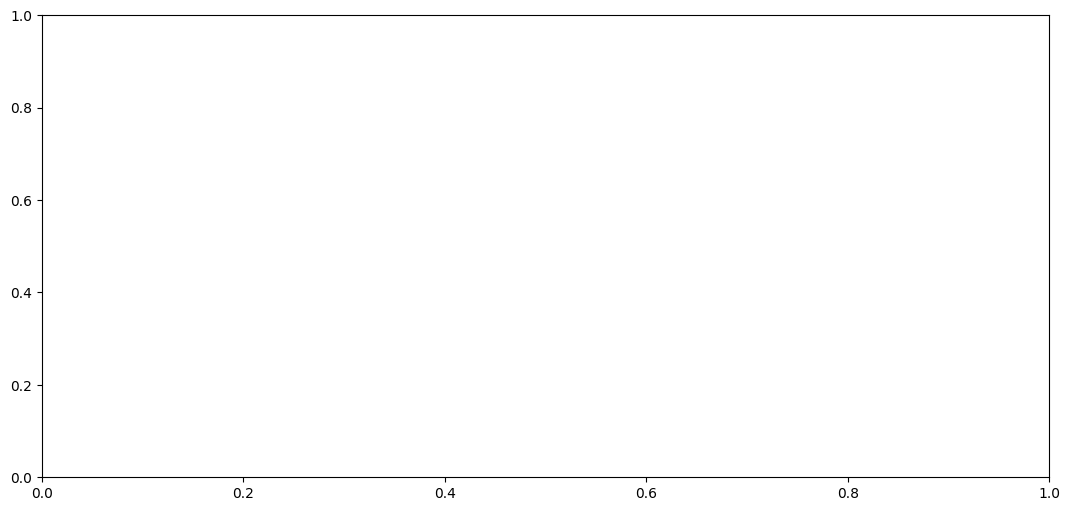

In [ ]:

# WEEK 3 — GENERATE ALL CHARTS
# EER by condition, DET curves, score distributions

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import shutil

# ── CHART 1: EER BY CONDITION BAR CHART ───────────────────
fig, ax = plt.subplots(figsize=(13, 6))

models     = ['Mel-GMM Baseline', 'Lightweight CNN',
              'Full CNN', 'Lightweight CNN-INT8']
conditions = ['Clean', 'G.711', 'Noise', 'Combined']
colors     = ['#64748B', '#FF6B00', '#EF4444', '#10B981']

eer_data = {}
for m in models:
    eer_data[m] = []
    for c in conditions:
        row = df_results[(df_results.Model==m) &
                         (df_results.Condition==c)]
        eer_data[m].append(row['EER (%)'].values[0])

x     = np.arange(len(conditions))
width = 0.2

for i, (model, color) in enumerate(zip(models, colors)):
    bars = ax.bar(x + i*width, eer_data[model],
                  width, label=model, color=color,
                  alpha=0.85, edgecolor='black', linewidth=0.5)
    for bar, val in zip(bars, eer_data[model]):
        ax.text(bar.get_x()+bar.get_width()/2,
                bar.get_height()+0.3,
                f'{val:.1f}', ha='center',
                va='bottom', fontsize=7.5,
                color=color, fontweight='bold')

ax.set_xlabel('Audio Condition', fontsize=12)
ax.set_ylabel('Equal Error Rate — EER (%)', fontsize=12)
ax.set_title('EER by Condition — All Models\n'
             'Waveform-Level Distortion (Lower is Better)',
             fontsize=13, fontweight='bold')
ax.set_xticks(x + width*1.5)
ax.set_xticklabels(conditions, fontsize=11)
ax.legend(loc='upper left', fontsize=9)
ax.grid(axis='y', alpha=0.3)
ax.set_ylim([0, 35])

plt.tight_layout()
plt.savefig('/content/eer_by_condition.png', dpi=150,
            bbox_inches='tight')
plt.show()
shutil.copy('/content/eer_by_condition.png',
            CHARTS_DIR/'eer_by_condition.png')
print('EER chart saved.')


# ── CHART 2: ACCURACY vs MAJORITY BASELINE ────────────────
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
fig.suptitle(
    'Model Accuracy vs Majority-Class Baseline (89.68%)\n'
    'Waveform-Level Distortion — ASVspoof 2019 LA',
    fontsize=13, fontweight='bold')

acc_colors = ['#64748B','#FF6B00','#EF4444','#10B981']

for ax, cond in zip(axes, conditions):
    accs = []
    for m in models:
        row = df_results[(df_results.Model==m) &
                         (df_results.Condition==cond)]
        accs.append(row['Acc (%)'].values[0])

    bars = ax.bar(range(len(models)), accs,
                  color=acc_colors, edgecolor='black',
                  linewidth=0.5, alpha=0.85)
    ax.axhline(y=89.68, color='red', linestyle='--',
               linewidth=1.5, label='Majority baseline')
    ax.set_title(cond, fontsize=11, fontweight='bold')
    ax.set_ylabel('Accuracy (%)' if cond=='Clean' else '')
    ax.set_xticks(range(len(models)))
    ax.set_xticklabels(['GMM','Light\nCNN','Full\nCNN','INT8'],
                       fontsize=8)
    ax.set_ylim([70, 95])
    ax.grid(axis='y', alpha=0.3)
    if cond == 'Clean':
        ax.legend(fontsize=8)
    for bar, val in zip(bars, accs):
        ax.text(bar.get_x()+bar.get_width()/2,
                bar.get_height()+0.2,
                f'{val:.1f}', ha='center',
                va='bottom', fontsize=8)

plt.tight_layout()
plt.savefig('/content/accuracy_vs_majority.png', dpi=150,
            bbox_inches='tight')
plt.show()
shutil.copy('/content/accuracy_vs_majority.png',
            CHARTS_DIR/'accuracy_vs_majority.png')
print('Accuracy vs majority baseline chart saved.')


# ── CHART 3: RA / FAR / MAR HEATMAP ──────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('RA / FAR / MAR Heatmap — All Models and Conditions\n'
             'Waveform-Level Distortion',
             fontsize=13, fontweight='bold')

metrics   = ['RA (%)', 'FAR (%)', 'MAR (%)']
titles    = ['Recognition Accuracy RA (%)\n(Higher is better)',
             'False Alarm Rate FAR (%)\n(Lower is better)',
             'Miss Alarm Rate MAR (%)\n(Lower is better)',]
cmaps     = ['Greens', 'Reds', 'Reds']

for ax, metric, title, cmap in zip(axes, metrics, titles, cmaps):
    data = np.zeros((len(models), len(conditions)))
    for i, m in enumerate(models):
        for j, c in enumerate(conditions):
            row = df_results[(df_results.Model==m) &
                             (df_results.Condition==c)]
            data[i, j] = row[metric].values[0]

    im = ax.imshow(data, cmap=cmap, aspect='auto',
                   vmin=0, vmax=100)
    ax.set_xticks(range(len(conditions)))
    ax.set_xticklabels(conditions, fontsize=9)
    ax.set_yticks(range(len(models)))
    ax.set_yticklabels(['Mel-GMM','Light CNN',
                        'Full CNN','INT8'], fontsize=9)
    ax.set_title(title, fontsize=10)
    plt.colorbar(im, ax=ax, fraction=0.046)

    for i in range(len(models)):
        for j in range(len(conditions)):
            ax.text(j, i, f'{data[i,j]:.1f}',
                   ha='center', va='center',
                   fontsize=9, fontweight='bold',
                   color='white' if data[i,j]>60 else 'black')

plt.tight_layout()
plt.savefig('/content/ra_far_mar_heatmap.png', dpi=150,
            bbox_inches='tight')
plt.show()
shutil.copy('/content/ra_far_mar_heatmap.png',
            CHARTS_DIR/'ra_far_mar_heatmap.png')
print('Heatmap saved.')


# ── SAVE UPDATED RESULTS CSV ──────────────────────────────
df_results.to_csv('/content/waveform_results_final.csv', index=False)
shutil.copy('/content/waveform_results_final.csv',
            RESULTS_DIR/'waveform_results_final.csv')

print('\nAll Week 3 charts saved to Drive.')
print('\nSummary of key EER values for paper:')
print('-'*50)
for c in conditions:
    print(f'\n{c}:')
    for m in models:
        row = df_results[(df_results.Model==m) &
                         (df_results.Condition==c)]
        eer = row['EER (%)'].values[0]
        acc = row['Acc (%)'].values[0]
        print(f'  {m:25s}  EER={eer:.2f}%  Acc={acc:.2f}%')

In [ ]:
# WEEK 4 — PER-ATTACK EER BREAKDOWN
# Tests each of the 13 attack types separately
# This shows which synthesis systems are hardest to detect

print('Computing per-attack EER breakdown...')
print('Attack types: A07 through A19 (13 systems)\n')

attack_types = sorted(df_eval[df_eval.label=='spoof']
                      .attack.unique())
bonafide_idx = df_eval[df_eval.label=='bonafide'].index.tolist()

print(f'Attack types found: {attack_types}')
print(f'Bonafide samples:   {len(bonafide_idx):,}')


def evaluate_per_attack(model, distortion_fn,
                        model_name, condition,
                        use_cpu=False, batch_size=128):
    """
    Evaluate model on each attack type separately.
    For each attack: combine all bonafide + that attack's spoof files.
    Returns dict of attack -> EER.
    """
    tgt = 'cpu' if use_cpu else device
    model = model.to(tgt).eval()
    attack_eers = {}

    for attack in attack_types:
        # Get indices for this attack
        spoof_idx = df_eval[df_eval.attack==attack].index.tolist()
        combined_idx = bonafide_idx + spoof_idx
        df_subset = df_eval.loc[combined_idx].reset_index(drop=True)
        y_sub = np.array([0 if l=='bonafide' else 1
                          for l in df_subset.label])

        # Extract features and run inference
        all_scores, batch_specs = [], []

        for idx, row in enumerate(df_subset.itertuples()):
            fp = EVAL_AUDIO / f'{row.filename}.flac'
            try:
                spec = load_and_distort(fp, distortion_fn)
            except Exception:
                spec = np.zeros((64,128), dtype=np.float32)
            batch_specs.append(spec)

            if len(batch_specs)==batch_size or \
               idx==len(df_subset)-1:
                X = torch.FloatTensor(
                    np.array(batch_specs)).unsqueeze(1).to(tgt)
                with torch.no_grad():
                    out = model(X).squeeze(1)
                all_scores.extend(out.cpu().numpy())
                batch_specs = []

        eer = compute_eer(y_sub, np.array(all_scores))
        attack_eers[attack] = eer

    return attack_eers


def evaluate_gmm_per_attack(distortion_fn):
    attack_eers = {}

    for attack in attack_types:
        spoof_idx    = df_eval[df_eval.attack==attack].index.tolist()
        combined_idx = bonafide_idx + spoof_idx
        df_subset    = df_eval.loc[combined_idx].reset_index(drop=True)
        y_sub = np.array([0 if l=='bonafide' else 1
                          for l in df_subset.label])

        all_scores, batch_flat = [], []
        CHUNK = 500

        for idx, row in enumerate(df_subset.itertuples()):
            fp = EVAL_AUDIO / f'{row.filename}.flac'
            try:
                spec = load_and_distort(fp, distortion_fn)
                batch_flat.append(spec.flatten())
            except Exception:
                batch_flat.append(
                    np.zeros(64*128, dtype=np.float32))

            if len(batch_flat)==CHUNK or \
               idx==len(df_subset)-1:
                X  = np.array(batch_flat)
                Xs = scaler.transform(X)
                sr = gmm_real.score_samples(Xs)
                sf = gmm_fake.score_samples(Xs)
                scores = sf - sr
                scores = (scores-scores.min())/(
                          scores.max()-scores.min()+1e-8)
                all_scores.extend(scores)
                batch_flat = []

        eer = compute_eer(y_sub, np.array(all_scores))
        attack_eers[attack] = eer

    return attack_eers


# Run per-attack evaluation on CLEAN audio only
# (most informative — shows inherent difficulty per attack type)
print('Evaluating per-attack EER on CLEAN audio...')
print('(This takes about 20-30 minutes)\n')

per_attack_results = {}

print('Mel-GMM Baseline...', flush=True)
per_attack_results['Mel-GMM Baseline'] = \
    evaluate_gmm_per_attack(None)
print('  done.')

print('Lightweight CNN...', flush=True)
per_attack_results['Lightweight CNN'] = \
    evaluate_per_attack(light_model, None, 'LightweightCNN',
                        'Clean')
print('  done.')

print('Full CNN...', flush=True)
per_attack_results['Full CNN'] = \
    evaluate_per_attack(full_model, None, 'FullCNN', 'Clean')
print('  done.')

# Print results table
print('\n' + '='*70)
print('PER-ATTACK EER (%) — CLEAN AUDIO — All Models')
print('='*70)
header = f'{"Attack":<8}'
for m in per_attack_results:
    header += f'{m:>20}'
print(header)
print('-'*70)

for attack in attack_types:
    row = f'{attack:<8}'
    for m in per_attack_results:
        eer = per_attack_results[m][attack]
        row += f'{eer:>20.2f}'
    print(row)

print('='*70)

# Save results
import json
with open('/content/per_attack_eer.json', 'w') as f:
    json.dump(per_attack_results, f, indent=2)
shutil.copy('/content/per_attack_eer.json',
            RESULTS_DIR/'per_attack_eer.json')
print('\nPer-attack results saved to Drive.')

Computing per-attack EER breakdown...
Attack types: A07 through A19 (13 systems)

Attack types found: ['A07', 'A08', 'A09', 'A10', 'A11', 'A12', 'A13', 'A14', 'A15', 'A16', 'A17', 'A18', 'A19']
Bonafide samples:   7,355
Evaluating per-attack EER on CLEAN audio...
(This takes about 20-30 minutes)

Mel-GMM Baseline...
  done.
Lightweight CNN...
  done.
Full CNN...
  done.

PER-ATTACK EER (%) — CLEAN AUDIO — All Models
Attack      Mel-GMM Baseline     Lightweight CNN            Full CNN
----------------------------------------------------------------------
A07                    48.92                0.23                0.10
A08                    43.40                2.49                5.62
A09                    49.64                0.13                0.15
A10                    43.58                0.54                0.45
A11                    42.59                0.48                0.41
A12                    49.13                0.29                0.33
A13                    48.

In [ ]:
# Get exact CPU model
import subprocess
result = subprocess.run(
    ['cat', '/proc/cpuinfo'],
    capture_output=True, text=True)

# Extract model name
for line in result.stdout.split('\n'):
    if 'model name' in line:
        print(line)
        break

model name	: Intel(R) Xeon(R) CPU @ 2.00GHz
